# OpenBCI patterns — layered, feature-space inverse

QC lives in `openbci_qc.py` / `openbci_qc.ipynb`. This notebook **calls** those functions (`oqc.qc_file`, `oqc.summarize_gate`). It does not re-implement USABLE / MARGINAL / ARTIFACT / RAILED.

**Typical order:** run `openbci_qc.ipynb`, Command-click the baseline CSVs then the distract CSVs, look at the gate. Then run this notebook with `USE_LAST_QC_RUN = True`. It reloads that file list, calls QC again, drops FAILs, and pools the rest. `USE_LAST_QC_RUN = False` uses the `SESSIONS` list below — still through `oqc.qc_file`.

Same filters (Cyton+Daisy, µV, **1–40 Hz** + 60 Hz notch, **45 s settle**, **10 s** windows). **attn_analysis** kernel.

**Pattern** is a *statistical signature*, not a nice voltage waveform. Ongoing EEG is structured noise: averaging raw 10 s traces should go toward a ripple. What we keep is:
- the spectrum as an equation (`log10 PSD(f) ≈ offset + slope · log10 f`, plus band peaks later with specparam/FOOOF if installed)
- band-power ratios over time (theta/beta, alpha/beta)
- relative band profile and (later) channel covariance

**Inverse** lives in *feature space*, not raw µV. A log-band-power shift or a spectral gain `H(f)` can make an **active** (`11→12`) window look like baseline *statistics*. It does not reconstruct the voltage you would have recorded at that moment. Copying the mean baseline spectrum always scores perfectly against that mean — that cheat is printed next to the real mapping.

**WiP** means *work in progress* (the Nov 17 write-up). It is not a software limit. Layers 4–5 are in this notebook. They **run on whatever you have** and switch from “fit on all windows, skip session CV” to **leave-one-session-out** as soon as a set has ≥2 days in `SESSIONS`. Pooling is **by set**: every extra Set 2 file joins the Set 2 pattern; Set 3 files build a separate glance pattern; Set 4 the same. Baseline days pool as set 1.

1. Session manifest, **call QC**, event-locked windows, features
2. Descriptive differences, CIs, time-on-task, movement, day-to-day drift
3. Simple mapping (band gain, `H(f)`) vs identity vs “always emit mean baseline”
4. Per-set pooling, log-band shift, affine/CORAL, ridge classifier, Bayesian ridge, covariance (Riemannian log-Euclidean), shuffle control, LOSO when n_days≥2, specparam/FOOOF if installed
5. Recovery windows (30 s after `12`) and mixed-effects `theta_beta ~ label + (1|session)` when statsmodels can fit

Windows inside one recording are correlated. The replicate is the **day**. Only files that **PASS** the QC gate are pooled (by `set`) on the shared USABLE montage.


In [1]:
from pathlib import Path
import os, sys
cwd = Path.cwd().resolve()
if (cwd / "analysis").is_dir() and (cwd / "experiments").is_dir():
    REPO_ROOT = cwd
elif cwd.name == "analysis":
    REPO_ROOT = cwd.parent
else:
    REPO_ROOT = cwd
os.chdir(REPO_ROOT)
sys.path.insert(0, str(REPO_ROOT / "analysis"))
print("REPO_ROOT:", REPO_ROOT)
print("kernel:", sys.executable)
%matplotlib inline
if "/envs/attn/" in sys.executable.replace("\\", "/") and "attn_analysis" not in sys.executable:
    print("Switch kernel to attn_analysis, then re-run from the top. Falling back to SVG plots.")
    %config InlineBackend.figure_format = "svg"


REPO_ROOT: /Users/sonipriyapaul/Downloads/AttentionSpan
kernel: /opt/miniconda3/envs/attn_analysis/bin/python


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.fft import rfft, irfft, rfftfreq
from scipy.signal import butter, sosfiltfilt, hilbert
from io import BytesIO
from IPython.display import SVG, display
import openbci_qc as oqc

OUT_DIR = REPO_ROOT / "analysis" / "outputs" / "openbci_patterns"
OUT_DIR.mkdir(parents=True, exist_ok=True)


def show_fig(fig, name):
    # SVG so the PsychoPy attn kernel does not try PNG. imshow still crashes attn;
    # catch that so later cells can run. Prefer the attn_analysis kernel.
    path = Path(OUT_DIR) / Path(name).with_suffix(".svg").name
    try:
        buf = BytesIO()
        fig.savefig(str(path), format="svg")
        fig.savefig(buf, format="svg")
        plt.close(fig)
        buf.seek(0)
        display(SVG(buf.getvalue()))
        print("saved", path)
    except Exception as e:
        plt.close(fig)
        print(f"skipped figure {name}: {e}")
        print("Switch kernel to attn_analysis (Kernel → Change Kernel) for plots.")

# QC constants — imported, not copied.
FS = oqc.FS
N_CH = oqc.N_CH
EXG_COLS = oqc.EXG_COLS
ACCEL_COLS = oqc.ACCEL_COLS
SETTLE_SEC = oqc.SETTLE_SEC
BP = oqc.BP
NOTCH_HZ = oqc.NOTCH_HZ
WIN_SEC = oqc.WIN_SEC
CHANNEL_LABELS = oqc.CHANNEL_LABELS
BANDS = oqc.BANDS
MIN_USABLE_CH = oqc.MIN_USABLE_CH
MIN_MINUTES = oqc.MIN_MINUTES
trapz = oqc.trapz

# Pattern-only.
INCLUDE_MARGINAL = False
MARK_SEND, MARK_UP, MARK_DOWN = 1.0, 11.0, 12.0
RECON_BANDS = {k: BANDS[k] for k in ("theta", "alpha", "beta")}
EEG_BANDS = list(BANDS)
colors = {
    "baseline": "#1f4e79",
    "reading": "#5b8fa8",
    "passive": "#d4a056",
    "active": "#b85c38",
    "recovery": "#6b7c59",
    "restored": "#2a7f62",
}
RECOVERY_SEC = 30.0  # after marker 12, until next 1 or this many seconds
print("QC module:", oqc.__file__)
print(f"gate: ≥{MIN_USABLE_CH} USABLE channels, ≥{MIN_MINUTES:.0f} min, filter {BP[0]:g}–{BP[1]:g} Hz")


QC module: /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/openbci_qc.py
gate: ≥8 USABLE channels, ≥5 min, filter 1–40 Hz


## Files to include

Each dict is one BrainFlow CSV. `condition` is `"baseline"` or `"distracted"`. Optional `set` is `2` (reply), `3` (glance), or `4` (auditory / eyes on screen) — same markers, different instruction.

- **baseline** — every clean window is baseline (no markers needed).
- **distracted** file, by marker (same `1`/`11`/`12` for sets 2, 3, and 4):
  - `1 → 11` = **passive** (notification out, not yet engaged)
  - `11 → 12` = **active** (pickup / glance / reply — main pattern for that set)
  - `12` + 30 s = **recovery**
  - anything else = **reading**

If a 10 s window overlaps several, priority is active > passive > recovery > reading. Pooling is **by `set`**: extra days with the same `set` join that set's pattern. Session 4 `*_20.csv` / `*_21.csv` are shorter copies of `*_0.csv` — do not enable them with `_0`.


In [3]:
REC = Path.home() / "Documents" / "OpenBCI_GUI" / "Recordings"

SESSIONS = [
    {
        "id": "baseline_s3",
        "condition": "baseline",
        "set": 1,
        "electrodes": "Cyton+Daisy dry",
        "task": "no-text baseline (same headset)",
        "enabled": True,
        "path": REC / "OpenBCISession_2026-10-20_12-23-57-SoniBaselineSession3"
               / "BrainFlow-RAW_2026-10-20_12-23-57-SoniBaselineSession3_0.csv",
    },
    {
        "id": "baseline_s4",
        "condition": "baseline",
        "set": 1,
        "electrodes": "Cyton+Daisy dry",
        "task": "no-text baseline (same headset)",
        "enabled": True,
        "path": REC / "OpenBCISession_2026-10-22_15-24-44-SoniBaselineSession4"
               / "BrainFlow-RAW_2026-10-22_15-24-44-SoniBaselineSession4_0.csv",
    },
    {
        "id": "distract_set2",
        "condition": "distracted",
        "set": 2,
        "electrodes": "Cyton+Daisy dry",
        "task": "reading a paper + text and reply",
        "enabled": True,
        "path": REC / "OpenBCISession_2026-10-25_14-23-26-SoniSet2"
               / "BrainFlow-RAW_2026-10-25_14-23-26-SoniSet2_0.csv",
    },
    # Copy a block, change id / set / path. Same set number → pooled into that set's pattern.
    # {"id": "set2_day2", "condition": "distracted", "set": 2, "electrodes": "Cyton+Daisy dry",
    #  "task": "reading + text and reply", "enabled": True, "path": REC / "..." / "....csv"},
    # {"id": "set3_day1", "condition": "distracted", "set": 3, "electrodes": "Cyton+Daisy dry",
    #  "task": "glance only", "enabled": True, "path": REC / "..." / "....csv"},
    # {"id": "set4_day1", "condition": "distracted", "set": 4, "electrodes": "Cyton+Daisy dry",
    #  "task": "auditory, eyes on screen", "enabled": True, "path": REC / "..." / "....csv"},
]

for s in SESSIONS:
    s["path"] = Path(s["path"])
    flag = "ON " if s.get("enabled", True) else "off"
    print(f"{flag:3} {s['id']:18} {s['condition']:12} exists={s['path'].exists()}  {s['path'].name}")


ON  baseline_s3        baseline     exists=True  BrainFlow-RAW_2026-10-20_12-23-57-SoniBaselineSession3_0.csv
ON  baseline_s4        baseline     exists=True  BrainFlow-RAW_2026-10-22_15-24-44-SoniBaselineSession4_0.csv
ON  distract_set2      distracted   exists=True  BrainFlow-RAW_2026-10-25_14-23-26-SoniSet2_0.csv


## Files from the QC notebook (or the list above)

`openbci_qc.ipynb` does the Finder multi-select and the quality check. Set `USE_LAST_QC_RUN = True` to take that file list (baseline vs distract, PASS/FAIL). Patterns then **calls** `oqc.qc_file` on each path so the filtered segments are in memory, and drops FAILs before pooling.

Leave it `False` to keep the `SESSIONS` list — still QC'd by calling the same module, not by a second copy of the rules.


In [4]:
USE_LAST_QC_RUN = True  # True → file list from the last openbci_qc.ipynb run

last = oqc.load_last_run(REPO_ROOT) if USE_LAST_QC_RUN else None
if last and last.get("files"):
    SESSIONS.clear()
    SESSIONS.extend(last["files"])
    print(f"Loaded {len(SESSIONS)} file(s) from {oqc.last_run_path(REPO_ROOT)}")
    print("Selected in openbci_qc.ipynb. This notebook will call oqc.qc_file on each.")
else:
    if USE_LAST_QC_RUN:
        print("No last_run.json yet. Using the SESSIONS list. Run openbci_qc.ipynb to pick CSVs.")
    else:
        print("USE_LAST_QC_RUN is False — using the SESSIONS list. QC is still oqc.qc_file.")

seen, uniq = set(), []
for s in SESSIONS:
    s["path"] = Path(s["path"])
    s["enabled"] = s.get("enabled", True)
    key = str(s["path"].resolve()) if s["path"].exists() else str(s["path"])
    if key in seen:
        print("skip duplicate", s["path"].name)
        continue
    seen.add(key)
    uniq.append(s)
SESSIONS[:] = uniq
for s in SESSIONS:
    flag = "ON " if s.get("enabled", True) else "off"
    gate = s.get("gate", "")
    extra = f"  last_gate={gate}" if gate else ""
    print(f"{flag:3} {s['id']:22} set={s.get('set')}  {s['condition']:12} exists={s['path'].exists()}  {s['path'].name}{extra}")


Loaded 3 file(s) from /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/openbci_qc/last_run.json
Selected in openbci_qc.ipynb. This notebook will call oqc.qc_file on each.
ON  baseline_s3            set=1  baseline     exists=True  BrainFlow-RAW_2026-10-20_12-23-57-SoniBaselineSession3_0.csv  last_gate=PASS
ON  baseline_s4            set=1  baseline     exists=True  BrainFlow-RAW_2026-10-22_15-24-44-SoniBaselineSession4_0.csv  last_gate=PASS
ON  distract_set2          set=2  distracted   exists=True  BrainFlow-RAW_2026-10-25_14-23-26-SoniSet2_0.csv  last_gate=PASS


## Pattern helpers (QC is imported)

Load / filter / window QC / channel verdicts come from `openbci_qc.py`. This cell is only markers (`1`/`11`/`12`), recovery windows, and the feature/inverse helpers.


In [5]:
def marker_times(mark, t_unix, values=(MARK_SEND, MARK_UP, MARK_DOWN)):
    if mark is None:
        return []
    m = np.asarray(mark, dtype=float)
    t = np.asarray(t_unix, dtype=float)
    return [(float(val), float(t[i])) for i, val in enumerate(m) if np.isfinite(val) and val in values]


def split_distraction_intervals(events, t_end):
    # Walk 1 / 11 / 12 in order.
    # passive = 1->11 (text sent, not yet engaged; 1->12 if they never hit 11).
    # active  = 11->12 (pickup / glance / reply).
    passive, active_iv = [], []
    pending_1 = pending_11 = None
    for v, t in events:
        if v == MARK_SEND:
            if pending_11 is not None:
                active_iv.append((pending_11, t))
                pending_11 = None
            if pending_1 is not None:
                passive.append((pending_1, t))
            pending_1 = t
        elif v == MARK_UP:
            if pending_1 is not None:
                passive.append((pending_1, t))
                pending_1 = None
            if pending_11 is not None:
                active_iv.append((pending_11, t))
            pending_11 = t
        elif v == MARK_DOWN:
            if pending_11 is not None:
                active_iv.append((pending_11, t))
                pending_11 = None
            elif pending_1 is not None:
                passive.append((pending_1, t))
                pending_1 = None
    if pending_11 is not None:
        active_iv.append((pending_11, t_end))
    if pending_1 is not None:
        passive.append((pending_1, t_end))
    return passive, active_iv


def recovery_intervals(events, t_end, rec_sec=RECOVERY_SEC):
    # After each 12, until the next 1 or rec_sec, whichever comes first.
    downs = [t for v, t in events if v == MARK_DOWN]
    sends = [t for v, t in events if v == MARK_SEND]
    ivals = []
    for t0 in downs:
        later = [t for t in sends if t > t0]
        t1 = t0 + float(rec_sec)
        if later:
            t1 = min(t1, later[0])
        t1 = min(t1, t_end)
        if t1 > t0:
            ivals.append((t0, t1))
    return ivals


def overlaps(t0, t1, ivals):
    return any((t0 < b) and (t1 > a) for a, b in ivals)


def bandpass_nd(x, fs, lo, hi):
    ny = fs / 2.0
    sos = butter(4, [lo / ny, min(hi / ny, 0.99)], btype="band", output="sos")
    return sosfiltfilt(sos, np.asarray(x, dtype=float), axis=0)


def add_segment_bands(segs, fs):
    for s in segs:
        s["bands"] = {n: bandpass_nd(s["filt"], fs, lo, hi) for n, (lo, hi) in BANDS.items()}


def window_features(sig, fs, band_slices=None):
    freqs, pxx = oqc._psd(sig, fs)
    powers = {n: oqc._band_power(freqs, pxx, lo, hi) for n, (lo, hi) in BANDS.items()}
    tot = sum(powers.values()) + 1e-12
    fmin = max(2.0, BP[0] * 1.2)
    m = (freqs >= fmin) & (freqs <= 30)
    if m.sum() >= 2:
        coef = np.polyfit(np.log10(freqs[m]), np.log10(pxx[m] + 1e-20), 1)
        slope, intercept = float(coef[0]), float(coef[1])
    else:
        slope, intercept = np.nan, np.nan
    feat = {"rms": float(np.std(sig)), "slope": slope, "intercept": intercept}
    for n, (lo, hi) in BANDS.items():
        xk = band_slices[n] if band_slices is not None else bandpass_nd(sig, fs, lo, hi)
        feat[f"rms_{n}"] = float(np.std(xk))
        feat[f"rel_{n}"] = 100.0 * powers[n] / tot
        feat[f"log_rms_{n}"] = float(np.log10(feat[f"rms_{n}"] + 1e-12))
    feat["theta_beta"] = feat["rms_theta"] / (feat["rms_beta"] + 1e-12)
    feat["alpha_beta"] = feat["rms_alpha"] / (feat["rms_beta"] + 1e-12)
    feat["env_mean"] = float(np.mean(np.abs(hilbert(sig))))
    return feat, freqs, pxx


def boot_mean_ci(x, n_boot=800, alpha=0.05, rng=None):
    # Percentile CI on the mean. Windows in one file are correlated, so this is optimistic.
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    if len(x) < 5:
        return np.nan, np.nan, np.nan
    rng = np.random.default_rng(0) if rng is None else rng
    means = [np.mean(rng.choice(x, size=len(x), replace=True)) for _ in range(n_boot)]
    lo, hi = np.percentile(means, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(np.mean(x)), float(lo), float(hi)


def restore_bandgain(sig, fs, gains, band_slices=None):
    x = np.asarray(sig, dtype=float)
    recon = np.zeros_like(x)
    used = np.zeros_like(x)
    for name, (lo, hi) in RECON_BANDS.items():
        xk = band_slices[name] if band_slices is not None else bandpass_nd(x, fs, lo, hi)
        recon += float(gains[name]) * xk
        used += xk
    return recon + (x - used)


def restore_spectral(sig, fs, freqs, gain):
    # Keep the window's phase; multiply FFT magnitude by H(f) = sqrt(PSD_baseline / PSD_active).
    n = len(sig)
    fr = rfftfreq(n, 1.0 / fs)
    g = np.interp(fr, freqs, gain)
    return irfft(rfft(sig) * g, n=n)


def cosine(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    if na < 1e-12 or nb < 1e-12:
        return np.nan
    return float(np.dot(a, b) / (na * nb))


def cohens_d(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    if len(a) < 2 or len(b) < 2:
        return np.nan
    v = ((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2)
    if v <= 0:
        return np.nan
    return float((a.mean() - b.mean()) / np.sqrt(v))

print("pattern helpers ready (QC = openbci_qc.qc_file)")


pattern helpers ready (QC = openbci_qc.qc_file)


## Call QC, then keep markers

Each file is sent through `oqc.qc_file` (the same load / filter / 10 s verdicts as `openbci_qc.ipynb`). Distracted files also print `1→11` / `11→12` / recovery counts. The next cell is the gate: files that fail do not enter the pool.


In [6]:
def process_session(spec):
    path = Path(spec["path"])
    print(f"\n=== {spec['id']}  ({spec['condition']})  {path.name}")
    rec = oqc.qc_file(path, verbose=True)
    fs, unix, mark = rec["fs"], rec["unix"], rec["mark"]
    hits = {}
    if mark is not None:
        vc = pd.Series(mark).value_counts()
        hits = {float(k): int(v) for k, v in vc.items()
                if float(k) in (MARK_SEND, MARK_UP, MARK_DOWN) or 100 <= float(k) <= 104}
        print("  markers:", hits or "none")
    add_segment_bands(rec["segs"], fs)
    print(rec["qc"][["ch", "label", "verdict", "pct_windows_clean", "median_rms_uV", "dominant"]].to_string(index=False))
    events = marker_times(mark, unix)
    t_end = float(unix[-1]) if unix is not None and len(unix) else rec["dur_min"] * 60.0
    if spec["condition"] == "distracted":
        ivals_passive, ivals_active = split_distraction_intervals(events, t_end)
        ivals_recovery = recovery_intervals(events, t_end)
    else:
        ivals_passive, ivals_active, ivals_recovery = [], [], []
    print(f"  set {spec.get('set', '-')}: passive 1→11 n={len(ivals_passive)}   "
          f"active 11→12 n={len(ivals_active)}   recovery n={len(ivals_recovery)}")
    return {
        "spec": spec, "path": path, "id": spec["id"],
        "condition": spec["condition"], "set": spec.get("set"),
        "task": spec.get("task", ""), "electrodes": spec.get("electrodes", "Cyton+Daisy dry"),
        "fs": fs, "unix": unix, "segs": rec["segs"], "win": rec["win"], "qc": rec["qc"],
        "events": events, "ivals_passive": ivals_passive, "ivals_active": ivals_active,
        "ivals_recovery": ivals_recovery,
        "dur_min": rec["dur_min"],
        "t0_unix": float(unix[0]) if unix is not None and len(unix) else 0.0,
        "n_mark": hits,
    }

missing = [s["id"] for s in SESSIONS if not Path(s["path"]).exists()]
if missing:
    raise FileNotFoundError("Missing files for " + ", ".join(missing) + ". Run openbci_qc.ipynb or edit SESSIONS.")
sessions = [process_session(s) for s in SESSIONS]



=== baseline_s3  (baseline)  BrainFlow-RAW_2026-10-20_12-23-57-SoniBaselineSession3_0.csv
QC  BrainFlow-RAW_2026-10-20_12-23-57-SoniBaselineSession3_0.csv
  302,838 samples  125 Hz  40.4 min
  5 segment(s) after 45s settle; 274,713 samples (36.6 min); filter 1–40 Hz + 60 Hz notch
  markers: none
 ch label       verdict  pct_windows_clean  median_rms_uV dominant
  0   Fp1 RAILED / dead           0.000000       0.000000        -
  1   Fp2 RAILED / dead           0.000000       0.000000        -
  2    C3        USABLE          99.539171      10.875041    delta
  3    C4        USABLE         100.000000      11.610331    delta
  4    P7      ARTIFACT          33.640553      63.439302    delta
  5    P8        USABLE          94.930876      10.502344    delta
  6    O1 RAILED / dead           0.000000       0.000000        -
  7    O2 RAILED / dead           0.000000       0.000000        -
  8    F7        USABLE          82.027650      22.108875    delta
  9    F8 RAILED / dead         

## QC gate — only files that pass are pooled

This is `oqc.summarize_gate` (same thresholds as the QC notebook). Failed files are dropped here so they never enter the montage intersection or the pattern.


Gate: ≥8 USABLE channels and ≥5 min.

--- baseline_s3  baseline  set=1  PASS
 ch label       verdict  pct_windows_clean  median_rms_uV dominant
  0   Fp1 RAILED / dead           0.000000       0.000000        -
  1   Fp2 RAILED / dead           0.000000       0.000000        -
  2    C3        USABLE          99.539171      10.875041    delta
  3    C4        USABLE         100.000000      11.610331    delta
  4    P7      ARTIFACT          33.640553      63.439302    delta
  5    P8        USABLE          94.930876      10.502344    delta
  6    O1 RAILED / dead           0.000000       0.000000        -
  7    O2 RAILED / dead           0.000000       0.000000        -
  8    F7        USABLE          82.027650      22.108875    delta
  9    F8 RAILED / dead           0.000000       0.000000        -
 10    F3        USABLE          99.539171      18.177739    delta
 11    F4        USABLE          93.087558      26.439467    delta
 12    T7        USABLE          93.548387       8.5

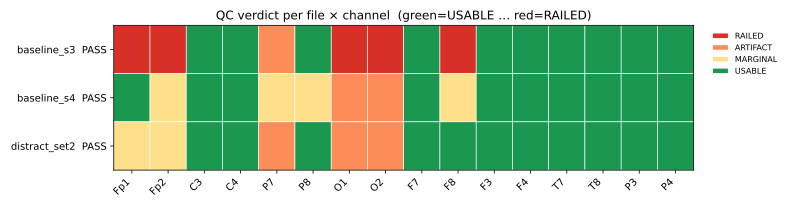

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/openbci_patterns/qc_gate_heatmap.svg
Proceeding with 3 file(s): 2 baseline, 1 distract


In [7]:
GATE = oqc.summarize_gate(sessions, verbose=True)
print(GATE.to_string(index=False))
GATE.to_csv(OUT_DIR / "qc_gate.csv", index=False)

heat = oqc.gate_heatmap_array(sessions)
fig, ax = plt.subplots(figsize=(11, max(2.4, 0.5 * len(sessions) + 1.4)))
oqc.draw_gate_heatmap(
    ax, heat,
    row_labels=[f"{S['id']}  {S['gate_row']['gate']}" for S in sessions],
    col_labels=[CHANNEL_LABELS[c] for c in range(N_CH)],
)
ax.set_title("QC verdict per file × channel  (green=USABLE … red=RAILED)")
fig.tight_layout()
show_fig(fig, "qc_gate_heatmap")

failed = [S["id"] for S in sessions if not S["qc_pass"]]
if failed:
    print("Dropped (failed QC gate):", failed)
sessions = [S for S in sessions if S["qc_pass"]]
if not sessions:
    raise RuntimeError("No file passed the QC gate. Fix electrodes/recordings or lower MIN_USABLE_CH in openbci_qc.py.")
n_base = sum(S["condition"] == "baseline" for S in sessions)
n_dist = sum(S["condition"] == "distracted" for S in sessions)
print(f"Proceeding with {len(sessions)} file(s): {n_base} baseline, {n_dist} distract")
if n_base == 0:
    print("WARNING: no baseline file passed. Pattern/inverse cells will skip until a baseline PASSes.")
if n_dist == 0:
    print("WARNING: no distract file passed. You can still look at the baseline pattern.")


## Shared montage

A channel has to be USABLE in **every** enabled file. That is what later plots use. Turn on `INCLUDE_MARGINAL` in the constants cell if you want to keep the borderline ones.


In [8]:
ok_sets = []
for S in sessions:
    ok = set(S["qc"].loc[S["qc"].verdict == "USABLE", "ch"].astype(int))
    if INCLUDE_MARGINAL:
        ok |= set(S["qc"].loc[S["qc"].verdict == "MARGINAL", "ch"].astype(int))
    S["ok_ch"] = sorted(ok)
    ok_sets.append(ok)
    print(f"{S['spec']['id']:18} usable {[(c, CHANNEL_LABELS[c]) for c in S['ok_ch']]}")
MONTAGE = sorted(set.intersection(*ok_sets)) if ok_sets and all(ok_sets) else []
if not MONTAGE:
    raise RuntimeError("No shared USABLE channels. Drop a bad session or set INCLUDE_MARGINAL = True.")
print("\nshared montage:", [(c, CHANNEL_LABELS[c]) for c in MONTAGE])


baseline_s3        usable [(2, 'C3'), (3, 'C4'), (5, 'P8'), (8, 'F7'), (10, 'F3'), (11, 'F4'), (12, 'T7'), (13, 'T8'), (14, 'P3'), (15, 'P4')]
baseline_s4        usable [(0, 'Fp1'), (2, 'C3'), (3, 'C4'), (8, 'F7'), (10, 'F3'), (11, 'F4'), (12, 'T7'), (13, 'T8'), (14, 'P3'), (15, 'P4')]
distract_set2      usable [(2, 'C3'), (3, 'C4'), (5, 'P8'), (8, 'F7'), (9, 'F8'), (10, 'F3'), (11, 'F4'), (12, 'T7'), (13, 'T8'), (14, 'P3'), (15, 'P4')]

shared montage: [(2, 'C3'), (3, 'C4'), (8, 'F7'), (10, 'F3'), (11, 'F4'), (12, 'T7'), (13, 'T8'), (14, 'P3'), (15, 'P4')]


## Layer 1 — session manifest

One row per file. This is the registry that makes pooling routine: date, electrodes, condition, set, QC montage, markers. Window counts fill in after the next section.

In [9]:
manifest_rows = []
for S in sessions:
    spec = S["spec"]
    usable = S["qc"].loc[S["qc"].verdict == "USABLE", "ch"].astype(int).tolist()
    marks = S.get("n_mark") or {}
    manifest_rows.append({
        "id": spec["id"],
        "condition": spec["condition"],
        "set": spec.get("set"),
        "electrodes": spec.get("electrodes", "Cyton+Daisy"),
        "task": spec.get("task", ""),
        "minutes": round(S["dur_min"], 1),
        "n_segments": len(S["segs"]),
        "n_usable_ch": len(usable),
        "usable": ",".join(CHANNEL_LABELS[c] for c in usable),
        "n_1": int(marks.get(1.0, 0)),
        "n_11": int(marks.get(11.0, 0)),
        "n_12": int(marks.get(12.0, 0)),
        "n_passive_bouts": len(S["ivals_passive"]),
        "n_active_bouts": len(S["ivals_active"]),
        "file": spec["path"].name,
    })
MANIFEST = pd.DataFrame(manifest_rows)
print(MANIFEST.drop(columns=["file"]).to_string(index=False))
print("shared montage after intersection will be computed in the next cells.")
MANIFEST.to_csv(OUT_DIR / "session_manifest.csv", index=False)
print("wrote", OUT_DIR / "session_manifest.csv")

           id  condition  set      electrodes                             task  minutes  n_segments  n_usable_ch                           usable  n_1  n_11  n_12  n_passive_bouts  n_active_bouts
  baseline_s3   baseline    1 Cyton+Daisy dry  no-text baseline (same headset)     40.4           5           10    C3,C4,P8,F7,F3,F4,T7,T8,P3,P4    0     0     0                0               0
  baseline_s4   baseline    1 Cyton+Daisy dry  no-text baseline (same headset)     37.8           6           10   Fp1,C3,C4,F7,F3,F4,T7,T8,P3,P4    0     0     0                0               0
distract_set2 distracted    2 Cyton+Daisy dry reading a paper + text and reply     35.9           3           11 C3,C4,P8,F7,F8,F3,F4,T7,T8,P3,P4   11    12    12               11              12
shared montage after intersection will be computed in the next cells.
wrote /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/openbci_patterns/session_manifest.csv


## Label 10 s windows

A window is kept only if **all** montage channels are clean in that window.

- `baseline` — **only** from files tagged baseline (set 1). Multiple baseline days are pooled here. Distracted files never enter this pattern.
- `active` — `11 → 12` inside a **distracted** file (main pattern for **that file's set**)
- `passive` — `1 → 11` and not active
- `recovery` — within 30 s after `12`
- `reading` — rest of a distracted file

Layer 4 pools `active` **by set** (set 2 reply vs set 3 glance vs set 4 auditory are separate). Baseline is always on its own.


In [10]:
rows = []
z_store, psd_store, env_store = {}, {}, {}
wlen = None
FREQS = None

for S in sessions:
    fs = S["fs"]
    w = int(WIN_SEC * fs)
    wlen = w if wlen is None else wlen
    mu, sd = {}, {}
    for c in MONTAGE:
        chunks = []
        for s in S["segs"]:
            wc = S["win"][(S["win"].ch == c) & (S["win"].seg == s["id"]) & (S["win"].clean)]
            for k in wc.win:
                chunks.append(s["filt"][int(k) * w:(int(k) + 1) * w, c])
        cat = np.concatenate(chunks) if chunks else np.array([0.0])
        mu[c] = float(cat.mean())
        sd[c] = float(cat.std()) if cat.std() > 1e-12 else 1.0
    S["z_mu"], S["z_sd"] = mu, sd
    for s in S["segs"]:
        for k in range(len(s["filt"]) // w):
            sl = slice(k * w, (k + 1) * w)
            sub = S["win"][(S["win"].seg == s["id"]) & (S["win"].win == k) & (S["win"].ch.isin(MONTAGE))]
            if len(sub) < len(MONTAGE) or not bool(sub.clean.all()):
                continue
            t0, t1 = float(sub.t0.iloc[0]), float(sub.t1.iloc[0])
            t_rel_min = (t0 - S["t0_unix"]) / 60.0 if np.isfinite(t0) else np.nan
            acc_rms = np.nan
            if s.get("accel") is not None and len(s["accel"]) >= (k + 1) * w:
                aa = s["accel"][sl]
                if np.isfinite(aa).any():
                    acc_rms = float(np.sqrt(np.nanmean(aa ** 2)))
            if S["spec"]["condition"] == "baseline":
                label = "baseline"
            elif overlaps(t0, t1, S["ivals_active"]):
                label = "active"
            elif overlaps(t0, t1, S["ivals_passive"]):
                label = "passive"
            elif overlaps(t0, t1, S.get("ivals_recovery") or []):
                label = "recovery"
            else:
                label = "reading"
            for c in MONTAGE:
                sig = s["filt"][sl, c]
                z = (sig - mu[c]) / sd[c]
                bsl = {n: s["bands"][n][sl, c] for n in BANDS}
                feat, freqs, pxx = window_features(sig, fs, bsl)
                if FREQS is None:
                    FREQS = freqs
                z_store.setdefault((S["spec"]["id"], label, c), []).append(z)
                psd_store.setdefault((S["spec"]["id"], label, c), []).append(pxx)
                env_store.setdefault((S["spec"]["id"], label, c), []).append(np.abs(hilbert(z)))
                rec = {"session": S["spec"]["id"], "condition": S["spec"]["condition"],
                       "set": S["spec"].get("set"),
                       "label": label, "seg": s["id"], "win": int(k), "ch": c,
                       "ch_label": CHANNEL_LABELS[c], "t0": t0, "t1": t1,
                       "t_rel_min": t_rel_min, "accel_rms": acc_rms}
                rec.update(feat)
                rows.append(rec)

W = pd.DataFrame(rows)
print(W.groupby(["session", "label"]).win.nunique().rename("n_windows").to_string())
print("rows (window × channel):", len(W))
uniq = W.drop_duplicates(["session", "set", "label", "seg", "win"])
print("\nPooling groups — baseline never includes distract files; each set is counted apart:")
print(uniq.groupby(["condition", "set", "label"]).agg(
    n_windows=("win", "size"), n_files=("session", "nunique")).to_string())
W.to_csv(OUT_DIR / "window_features.csv", index=False)
print("wrote", OUT_DIR / "window_features.csv")


session        label   
baseline_s3    baseline     96
baseline_s4    baseline    115
distract_set2  active       63
               passive       6
               reading      43
               recovery     28
rows (window × channel): 4518

Pooling groups — baseline never includes distract files; each set is counted apart:
                         n_windows  n_files
condition  set label                       
baseline   1   baseline        315        2
distracted 2   active           88        1
               passive           6        1
               reading          63        1
               recovery         30        1
wrote /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/openbci_patterns/window_features.csv


## How much data survived

This is the first result: counts only. `active` (`11→12`) is the main distracted class and is usually shorter than `passive` (`1→11`) plus `reading`.


label
baseline    315
reading      63
passive       6
active       88
recovery     30
minutes ≈ windows × 10 / 60
label
baseline    52.5
reading     10.5
passive      1.0
active      14.7
recovery     5.0


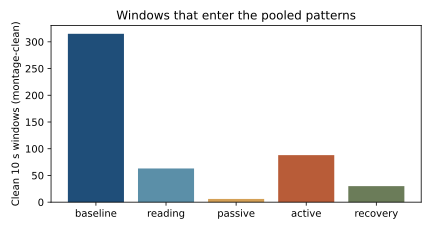

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/openbci_patterns/n_windows.svg


In [11]:
n_dist_sets = int(W.loc[W.condition == "distracted", "set"].nunique()) if "condition" in W.columns else 0
if n_dist_sets > 1:
    print(f"NOTE: {n_dist_sets} distract sets are loaded. The bars below still use one 'active' class.")
    print("Layer 4 splits set 2 / 3 / 4. Baseline in these plots is still only the baseline files.")
LABELS = [lb for lb in ("baseline", "reading", "passive", "active", "recovery") if (W.label == lb).any()]
counts = W.drop_duplicates(["session", "label", "seg", "win"]).groupby("label").size().reindex(LABELS)
print(counts.rename("n unique 10s windows").to_string())
print("minutes ≈ windows × 10 / 60")
print((counts * WIN_SEC / 60).round(1).rename("minutes").to_string())

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(range(len(LABELS)), counts.values, color=[colors[lb] for lb in LABELS])
ax.set_xticks(range(len(LABELS)))
ax.set_xticklabels(LABELS)
ax.set_ylabel("Clean 10 s windows (montage-clean)")
ax.set_title("Windows that enter the pooled patterns")
fig.tight_layout()
show_fig(fig, "n_windows")


## Band profile

Median **relative** power (each window sums to 100%). This is the simple “shape” of baseline vs passive vs active. Delta is large because the filter starts at 1 Hz — do not read it as sleep. Compare **theta / alpha / beta**.


median relative band power (%)
          rel_delta  rel_theta  rel_alpha  rel_beta  rel_gamma
label                                                         
active         48.8       18.4        8.9      15.9        4.7
baseline       54.9       22.1        8.1      10.5        2.7
passive        46.7       20.0        9.5      15.1        4.2
reading        49.6       18.1        9.2      16.4        4.7
recovery       49.9       18.5        8.8      16.0        4.4

median band RMS (µV)
          rms_delta  rms_theta  rms_alpha  rms_beta  rms_gamma     rms
label                                                                 
active        6.550      4.069      2.776     3.564      1.911   9.982
baseline      8.034      4.956      3.025     3.414      1.702  11.160
passive       7.204      4.888      3.148     3.792      2.102  10.947
reading       6.580      4.051      2.862     3.607      1.931   9.948
recovery      6.977      4.288      2.873     3.637      1.918  10.410


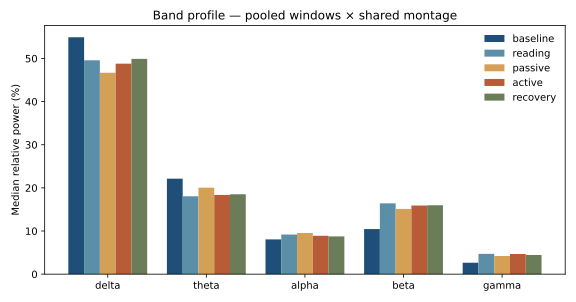

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/openbci_patterns/band_profile.svg


In [12]:
band_profile = W.groupby("label")[[f"rel_{k}" for k in EEG_BANDS]].median()
rms_profile = W.groupby("label")[[f"rms_{k}" for k in EEG_BANDS] + ["rms"]].median()
print("median relative band power (%)")
print(band_profile.round(1).to_string())
print("\nmedian band RMS (µV)")
print(rms_profile.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(EEG_BANDS))
width = 0.8 / max(len(LABELS), 1)
for i, lb in enumerate(LABELS):
    vals = [band_profile.loc[lb, f"rel_{k}"] for k in EEG_BANDS]
    ax.bar(x + (i - (len(LABELS) - 1) / 2) * width, vals, width, color=colors[lb], label=lb)
ax.set_xticks(x)
ax.set_xticklabels(EEG_BANDS)
ax.set_ylabel("Median relative power (%)")
ax.set_title("Band profile — pooled windows × shared montage")
ax.legend(frameon=False)
fig.tight_layout()
show_fig(fig, "band_profile")


## Layer 2 — differences with CIs, time-on-task, movement

Bootstrap CIs are on the **window** mean. Windows in one file are not independent, so the intervals are optimistic. The real replicate is a *session*. Theta/beta and alpha/beta are the band-behavior features. Accel RMS is a movement confound check (typing / picking up the phone), not EEG.

log-band RMS and ratios (window means, montage-averaged)
          theta_beta  alpha_beta  log_rms_theta  log_rms_alpha  log_rms_beta
label                                                                       
active         1.203       0.792          0.604          0.438         0.550
baseline       1.638       0.903          0.727          0.484         0.528
passive        1.242       0.828          0.702          0.498         0.597
reading        1.224       0.816          0.609          0.454         0.553
recovery       1.220       0.805          0.616          0.457         0.561

bootstrap mean relative power (%)  [optimistic: windows are correlated]
   label  band  mean  ci95_lo  ci95_hi  n_win
baseline delta 54.00    53.38    54.65    315
baseline theta 23.21    22.81    23.61    315
baseline alpha  8.38     8.17     8.62    315
baseline  beta 11.37    11.09    11.63    315
baseline gamma  3.03     2.94     3.12    315
 reading delta 51.03    49.44    53.00     63
 reading 

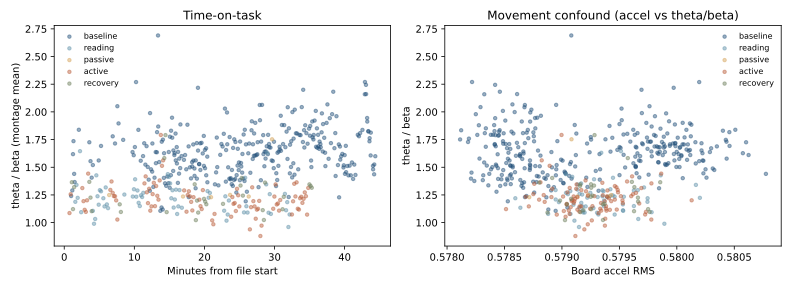

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/openbci_patterns/time_on_task_accel.svg

median accel RMS by label (higher → more board motion)
label
active      0.5792
baseline    0.5791
passive     0.5792
reading     0.5793
recovery    0.5793


In [13]:
# One row per unique window (mean across montage channels) so time-on-task isn't 9x duplicated.
Wwin = (W.groupby(["session", "label", "seg", "win"], as_index=False)
          .agg(t_rel_min=("t_rel_min", "mean"),
               accel_rms=("accel_rms", "mean"),
               theta_beta=("theta_beta", "mean"),
               alpha_beta=("alpha_beta", "mean"),
               **{f"rel_{k}": (f"rel_{k}", "mean") for k in EEG_BANDS},
               **{f"log_rms_{k}": (f"log_rms_{k}", "mean") for k in EEG_BANDS}))

print("log-band RMS and ratios (window means, montage-averaged)")
print(Wwin.groupby("label")[["theta_beta", "alpha_beta"] + [f"log_rms_{k}" for k in ("theta", "alpha", "beta")]].median().round(3).to_string())

print("\nbootstrap mean relative power (%)  [optimistic: windows are correlated]")
ci_rows = []
for lb in LABELS:
    sub = Wwin[Wwin.label == lb]
    for k in EEG_BANDS:
        mu, lo, hi = boot_mean_ci(sub[f"rel_{k}"])
        ci_rows.append({"label": lb, "band": k, "mean": mu, "ci95_lo": lo, "ci95_hi": hi, "n_win": len(sub)})
CI = pd.DataFrame(ci_rows)
print(CI.round(2).to_string(index=False))

# Time-on-task: does the active signature just grow with fatigue?
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
ax = axes[0]
for lb in LABELS:
    sub = Wwin[Wwin.label == lb]
    ax.scatter(sub.t_rel_min, sub.theta_beta, s=12, alpha=0.45, color=colors[lb], label=lb)
ax.set_xlabel("Minutes from file start")
ax.set_ylabel("theta / beta (montage mean)")
ax.set_title("Time-on-task")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
for lb in LABELS:
    sub = Wwin[Wwin.label == lb]
    ax.scatter(sub.accel_rms, sub.theta_beta, s=12, alpha=0.45, color=colors[lb], label=lb)
ax.set_xlabel("Board accel RMS")
ax.set_ylabel("theta / beta")
ax.set_title("Movement confound (accel vs theta/beta)")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
show_fig(fig, "time_on_task_accel")

print("\nmedian accel RMS by label (higher → more board motion)")
print(Wwin.groupby("label").accel_rms.median().round(4).to_string())

## Mean PSD

Average spectrum of the same windows. Dashed line is a 1/f fit on 2–30 Hz. If baseline and **active** (`11→12`) differ, you should see it here before looking at any restore. Passive (`1→11`) is the setup period.


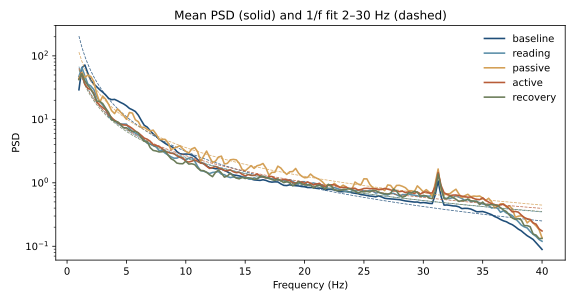

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/openbci_patterns/mean_psd.svg


In [14]:
def stack_arr(store, label, ch):
    parts = [np.stack(v) for (sid, lb, c), v in store.items() if lb == label and c == ch and len(v)]
    return np.concatenate(parts, axis=0) if parts else None

wave = {}
for lb in LABELS:
    z_means, env_means, psds = [], [], []
    for c in MONTAGE:
        Z = stack_arr(z_store, lb, c)
        E = stack_arr(env_store, lb, c)
        P = stack_arr(psd_store, lb, c)
        if Z is None:
            continue
        z_means.append(Z.mean(axis=0))
        env_means.append(E.mean(axis=0))
        psds.append(P.mean(axis=0))
    wave[lb] = {
        "z": np.mean(z_means, axis=0),
        "z_sem": np.std(z_means, axis=0) / np.sqrt(len(z_means)),
        "env": np.mean(env_means, axis=0),
        "psd": np.mean(psds, axis=0),
    }

def fit_one_over_f(freqs, pxx):
    m = (freqs >= 2.0) & (freqs <= 30.0) & np.isfinite(pxx) & (pxx > 0)
    coef = np.polyfit(np.log10(freqs[m]), np.log10(pxx[m]), 1)
    return float(coef[0]), float(coef[1])

eq = {lb: dict(zip(("slope", "intercept"), fit_one_over_f(FREQS, wave[lb]["psd"]))) for lb in LABELS}

fig, ax = plt.subplots(figsize=(8, 4.2))
m = (FREQS >= 1) & (FREQS <= 40)
for lb in LABELS:
    ax.semilogy(FREQS[m], wave[lb]["psd"][m], color=colors[lb], lw=1.6, label=lb)
    fit = 10 ** (eq[lb]["intercept"] + eq[lb]["slope"] * np.log10(FREQS[m]))
    ax.semilogy(FREQS[m], fit, color=colors[lb], lw=0.8, ls="--", alpha=0.85)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("PSD")
ax.set_title("Mean PSD (solid) and 1/f fit 2–30 Hz (dashed)")
ax.legend(frameon=False)
fig.tight_layout()
show_fig(fig, "mean_psd")


## Negative control: mean waveform (not the pattern)

This is here so the “nice waveform” idea can fail in public. Ongoing EEG is not phase-locked, so the average 10 s z-trace should collapse toward a ripple. The pattern we actually use is the spectrum / band profile above, not this plot. If this average looks like a clean ERP, something is wrong (likely a filter artifact or a locked noise).


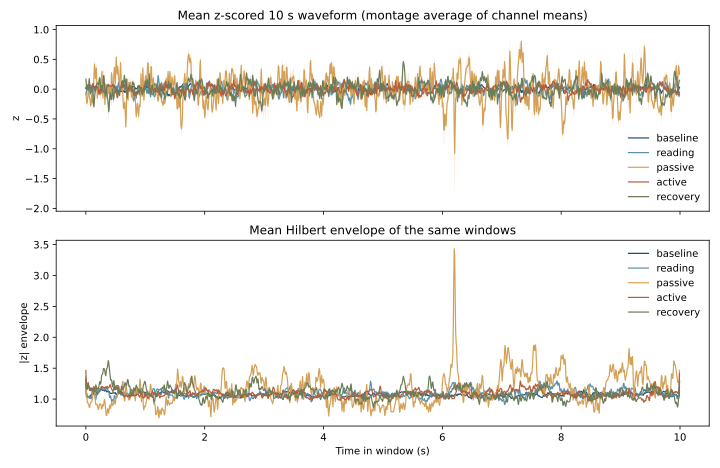

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/openbci_patterns/mean_waveform_envelope.svg


In [15]:
t = np.arange(wlen) / sessions[0]["fs"]
fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
ax = axes[0]
for lb in LABELS:
    ax.plot(t, wave[lb]["z"], color=colors[lb], lw=1.2, label=lb)
    ax.fill_between(t, wave[lb]["z"] - wave[lb]["z_sem"], wave[lb]["z"] + wave[lb]["z_sem"],
                    color=colors[lb], alpha=0.18, linewidth=0)
ax.set_ylabel("z")
ax.set_title("Mean z-scored 10 s waveform (montage average of channel means)")
ax.legend(frameon=False)
ax = axes[1]
for lb in LABELS:
    ax.plot(t, wave[lb]["env"], color=colors[lb], lw=1.2, label=lb)
ax.set_xlabel("Time in window (s)")
ax.set_ylabel("|z| envelope")
ax.set_title("Mean Hilbert envelope of the same windows")
ax.legend(frameon=False)
fig.tight_layout()
show_fig(fig, "mean_waveform_envelope")


## Equation of each condition

On 2–30 Hz the mean spectrum is close to

\(\log_{10} \mathrm{PSD}(f) \approx c + s\,\log_{10} f\)

That is the compact pattern: two numbers per condition. More data days shrink the uncertainty on \(c\) and \(s\), they should not jump around if the pattern is real.


In [16]:
print("log10 PSD(f)  ≈  intercept  +  slope * log10(f)     [2–30 Hz, montage mean]\n")
for lb in LABELS:
    print(f"  {lb:10}  {eq[lb]['intercept']:+.3f}  +  {eq[lb]['slope']:+.3f} * log10(f)")
if "baseline" in eq and "active" in eq:
    ds = eq["baseline"]["slope"] - eq["active"]["slope"]
    dc = eq["baseline"]["intercept"] - eq["active"]["intercept"]
    print(f"\n  difference (baseline − active 11→12):  Δintercept = {dc:+.3f}   Δslope = {ds:+.3f}")
    print("  restore spectrum:  log10 PSD_hat(f) ≈ log10 PSD_active(f) + Δintercept + Δslope * log10(f)")


log10 PSD(f)  ≈  intercept  +  slope * log10(f)     [2–30 Hz, montage mean]

  baseline    +2.312  +  -1.818 * log10(f)
  reading     +1.831  +  -1.429 * log10(f)
  passive     +2.059  +  -1.504 * log10(f)
  active      +1.807  +  -1.379 * log10(f)
  recovery    +1.786  +  -1.398 * log10(f)

  difference (baseline − active 11→12):  Δintercept = +0.505   Δslope = -0.439
  restore spectrum:  log10 PSD_hat(f) ≈ log10 PSD_active(f) + Δintercept + Δslope * log10(f)


## Where they differ (Cohen's d)

Positive = more of that relative band in **baseline** than in **active** (`11→12`). This is per channel, so you can see if one site is carrying the contrast. \(|d|\gtrsim 0.5\) is a difference worth keeping an eye on as you add days.


baseline vs active (11→12)
    theta  alpha  beta
C3   0.51  -0.87 -0.73
C4  -0.32  -0.18 -0.48
F7   1.22  -0.11 -0.45
F3   0.68  -0.81 -2.42
F4   0.97  -0.35 -1.06
T7   1.28  -0.29 -3.88
T8   0.76  -0.11 -1.19
P3   0.96   0.21 -0.42
P4   0.39   0.28 -0.28


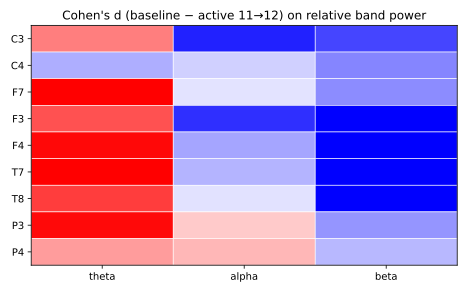

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/openbci_patterns/cohens_d.svg


In [17]:
if "baseline" not in LABELS or "active" not in LABELS:
    print("Need baseline and active (11→12) windows for this cell.")
else:
    dmat = np.zeros((len(MONTAGE), len(RECON_BANDS)))
    for i, c in enumerate(MONTAGE):
        for j, k in enumerate(RECON_BANDS):
            a = W[(W.label == "baseline") & (W.ch == c)][f"rel_{k}"]
            b = W[(W.label == "active") & (W.ch == c)][f"rel_{k}"]
            dmat[i, j] = cohens_d(a, b)
    dtab = pd.DataFrame(dmat, index=[CHANNEL_LABELS[c] for c in MONTAGE], columns=list(RECON_BANDS))
    print("baseline vs active (11→12)")
    print(dtab.round(2).to_string())
    fig, ax = plt.subplots(figsize=(6.5, max(3.5, 0.32 * len(MONTAGE) + 1.2)))
    from matplotlib.patches import Rectangle
    for i in range(dmat.shape[0]):
        for j in range(dmat.shape[1]):
            v = float(dmat[i, j]) if np.isfinite(dmat[i, j]) else 0.0
            v = max(-1.0, min(1.0, v))
            if v >= 0:
                color = (1.0, 1.0 - v, 1.0 - v)
            else:
                color = (1.0 + v, 1.0 + v, 1.0)
            ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, facecolor=color, edgecolor="white", lw=0.6))
    ax.set_xlim(-0.5, dmat.shape[1] - 0.5)
    ax.set_ylim(dmat.shape[0] - 0.5, -0.5)
    ax.set_xticks(range(len(RECON_BANDS)))
    ax.set_xticklabels(list(RECON_BANDS))
    ax.set_yticks(range(len(MONTAGE)))
    ax.set_yticklabels([CHANNEL_LABELS[c] for c in MONTAGE])
    ax.set_title("Cohen's d (baseline − active 11→12) on relative band power")
    fig.tight_layout()
    show_fig(fig, "cohens_d")

## Layer 2 — is the contrast bigger than day-to-day baseline drift?

Two baseline days let us ask whether baseline vs **active** is larger than baseline_s3 vs baseline_s4. If the two baseline days already differ as much as baseline vs phone, the “distracted pattern” is not ready to invert. This is the closest we can get to session-level comparison until a second distract day exists.

In [18]:
base_days = sorted(Wwin[Wwin.label == "baseline"].session.unique())
print("baseline sessions:", list(base_days))
feat_cols = [f"rel_{k}" for k in ("theta", "alpha", "beta")] + ["theta_beta", "alpha_beta"]

def session_mean(session=None, label=None):
    sub = Wwin
    if session is not None:
        sub = sub[sub.session == session]
    if label is not None:
        sub = sub[sub.label == label]
    return sub[feat_cols].median()

def l2(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return float(np.linalg.norm(a - b))

if len(base_days) >= 2:
    m0 = session_mean(base_days[0], "baseline")
    m1 = session_mean(base_days[1], "baseline")
    print(f"L2  {base_days[0]} vs {base_days[1]} (baseline vs baseline): {l2(m0, m1):.3f}")
else:
    print("Only one baseline session — cannot measure day-to-day drift yet.")
    m0 = session_mean(label="baseline")

m_base = session_mean(label="baseline")
m_act = session_mean(label="active") if "active" in LABELS else None
m_read = session_mean(label="reading") if "reading" in LABELS else None
if m_act is not None:
    print(f"L2  pooled baseline vs active:  {l2(m_base, m_act):.3f}")
if m_read is not None:
    print(f"L2  pooled baseline vs reading: {l2(m_base, m_read):.3f}")
print("If baseline-vs-active is not clearly larger than baseline-vs-baseline, do not trust an inverse yet.")
print("\nmedian feature vectors")
print(pd.DataFrame({"baseline": m_base, "active": m_act, "reading": m_read}).round(3).to_string())

baseline sessions: ['baseline_s3', 'baseline_s4']
L2  baseline_s3 vs baseline_s4 (baseline vs baseline): 1.181
L2  pooled baseline vs active:  6.927
L2  pooled baseline vs reading: 7.449
If baseline-vs-active is not clearly larger than baseline-vs-baseline, do not trust an inverse yet.

median feature vectors
            baseline  active  reading
rel_theta     22.809  19.233   17.955
rel_alpha      8.211   9.103    9.372
rel_beta      11.279  17.127   16.793
theta_beta     1.638   1.203    1.224
alpha_beta     0.903   0.792    0.816


## Simple restore: three band gains

Scale theta / alpha / beta of an **active** (`11→12`) window so median RMS matches baseline. Residual (delta + gamma) is left alone — that is where dry-electrode motion lives.

\(\hat{x}(t) = a_\theta x_\theta(t) + a_\alpha x_\alpha(t) + a_\beta x_\beta(t) + r_{\delta,\gamma}(t)\)

\(a_k = \mathrm{median\,RMS}_{\mathrm{baseline},k} \,/\, \mathrm{median\,RMS}_{\mathrm{active},k}\)


In [19]:
if "baseline" not in LABELS or "active" not in LABELS:
    gains = {}
    print("Need baseline and active (11→12) windows.")
else:
    gains = {k: float(rms_profile.loc["baseline", f"rms_{k}"] / (rms_profile.loc["active", f"rms_{k}"] + 1e-12))
             for k in RECON_BANDS}
    print("a_k  (all active 11→12 windows vs all baseline windows)")
    for k, a in gains.items():
        print(f"  a_{k} = {a:.3f}")
    print("\nsession-wise a_k (does the next distracted day agree?)")
    base_rms = W[W.label == "baseline"][[f"rms_{k}" for k in RECON_BANDS]].median()
    for sid, sub in W[W.label == "active"].groupby("session"):
        med = sub[[f"rms_{k}" for k in RECON_BANDS]].median()
        bits = [f"a_{k}={base_rms[f'rms_{k}'] / (med[f'rms_{k}'] + 1e-12):.3f}" for k in RECON_BANDS]
        print(f"  {sid}:  " + "  ".join(bits))


a_k  (all active 11→12 windows vs all baseline windows)
  a_theta = 1.218
  a_alpha = 1.090
  a_beta = 0.958

session-wise a_k (does the next distracted day agree?)
  distract_set2:  a_theta=1.218  a_alpha=1.090  a_beta=0.958


## Better restore: spectral gain H(f)

The three numbers above only stretch whole bands. A fuller difference pattern is a **frequency-dependent gain** estimated from mean PSDs:

\(H(f) = \sqrt{\mathrm{PSD}_\mathrm{baseline}(f)\,/\,\mathrm{PSD}_\mathrm{active}(f)}\)

Applied to an **active** (`11→12`) window: keep its phase, reshape its spectrum. Last 30% of those windows are held out so we are not scoring the same data we fit.


held-out active (11→12) windows: 26 of 88
train band gains: {'theta': 1.203, 'alpha': 1.073, 'beta': 0.946}


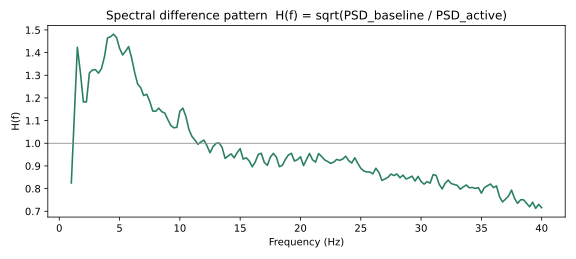

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/openbci_patterns/spectral_gain_H.svg


In [20]:
if "baseline" not in LABELS or "active" not in LABELS:
    print("Need baseline and active (11→12) windows.")
else:
    active_keys = sorted(W[W.label == "active"][["session", "seg", "win"]].drop_duplicates().itertuples(index=False, name=None))
    n_hold = max(1, int(0.30 * len(active_keys)))
    hold_set = set(active_keys[-n_hold:])
    train_set = set(active_keys[:-n_hold])
    keys = list(zip(W.session, W.seg, W.win))
    train_mask = np.array([(k in train_set) for k in keys]) if train_set else (W.label == "active").to_numpy()
    Wtr = W[(W.label == "active").to_numpy() & train_mask]

    base_rms = W[W.label == "baseline"][[f"rms_{k}" for k in RECON_BANDS]].median()
    act_rms = Wtr[[f"rms_{k}" for k in RECON_BANDS]].median() if len(Wtr) else W[W.label == "active"][[f"rms_{k}" for k in RECON_BANDS]].median()
    gains_cv = {k: float(base_rms[f"rms_{k}"] / (act_rms[f"rms_{k}"] + 1e-12)) for k in RECON_BANDS}

    H = np.sqrt((wave["baseline"]["psd"] + 1e-20) / (wave["active"]["psd"] + 1e-20))
    print("held-out active (11→12) windows:", n_hold, "of", len(active_keys))
    print("train band gains:", {k: round(v, 3) for k, v in gains_cv.items()})

    fig, ax = plt.subplots(figsize=(8, 3.6))
    m = (FREQS >= 1) & (FREQS <= 40)
    ax.plot(FREQS[m], H[m], color="#2a7f62", lw=1.6)
    ax.axhline(1.0, color="#888", lw=0.8)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("H(f)")
    ax.set_title("Spectral difference pattern  H(f) = sqrt(PSD_baseline / PSD_active)")
    fig.tight_layout()
    show_fig(fig, "spectral_gain_H")


## Layer 3 — mapping vs naive competitors (held-out active windows)

The mapping is in **feature space**: band RMS gains, or `H(f)` on the spectrum, phase unchanged. Scores compare the window's *relative band profile* to the baseline median.

Naive competitors that must be beaten, or at least reported:
- **identity** — leave the active window as-is (`cos_raw`)
- **always emit mean baseline** — cosine = 1, L2 = 0 by construction. This is the cheat. A mapping that just pastes the baseline mean is not an inverse of *this* window.

Hold-out is the last 30% of **windows in the only distract file**, not leave-one-session-out. That needs a second distract day.


          cos_raw  cos_gain  cos_spec  l2_raw  l2_gain  l2_spec
ch_label                                                       
C3          0.958     0.946     0.964  15.212   17.089   12.191
C4          0.941     0.897     0.925  18.175   25.064   21.135
F3          0.989     0.988     0.991   9.207    8.654   10.193
F4          0.980     0.976     0.981  12.772   12.826   14.668
F7          0.964     0.973     0.975  22.373   18.191   20.684
P3          0.960     0.954     0.979  16.794   17.878   10.800
P4          0.927     0.919     0.964  21.756   22.940   14.344
T7          0.746     0.780     0.883  40.029   36.995   26.842
T8          0.973     0.976     0.989  12.904   11.747    8.584

cosine to baseline profile:  identity 0.938  band-gain 0.934  spectral 0.961  cheat(mean baseline)=1.000
L2 to baseline profile:      identity 18.80  band-gain 19.04  spectral 15.49  cheat=0.00
Spectral H(f) should beat identity. Beating the cheat is not the goal — the cheat ignores the window.

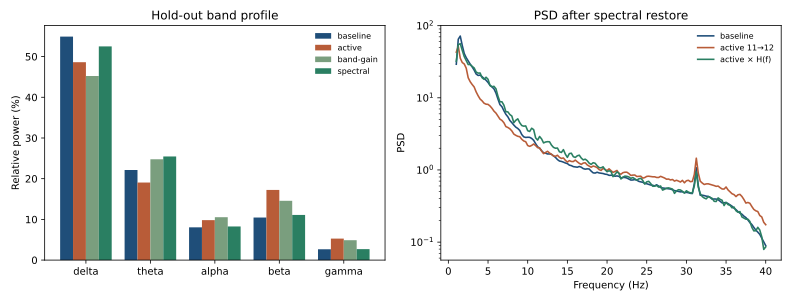

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/openbci_patterns/restore_holdout.svg


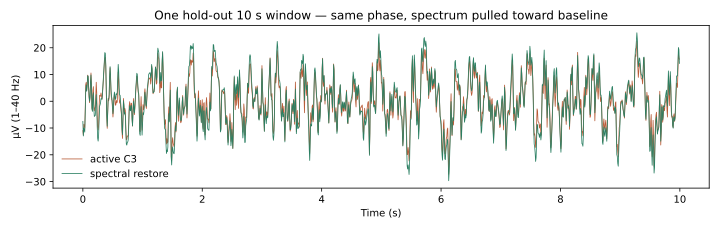

saved /Users/sonipriyapaul/Downloads/AttentionSpan/analysis/outputs/openbci_patterns/restore_example_window.svg

Equations used on hold-out:
  band-gain:  x_hat(t) = 1.203·x_theta(t) + 1.073·x_alpha(t) + 0.946·x_beta(t) + residual_delta_gamma(t)
  spectral:   X_hat(f) = H(f) · X_active(f)   (phase unchanged)


In [21]:
if "baseline" not in LABELS or "active" not in LABELS:
    print("Need baseline and active (11→12) windows.")
else:
    rec_rows = []
    example = None
    psd_hat_g, psd_hat_s = [], []
    target = np.array([band_profile.loc["baseline", f"rel_{k}"] for k in EEG_BANDS])
    for S in sessions:
        if S["spec"]["condition"] != "distracted":
            continue
        fs, w = S["fs"], int(WIN_SEC * S["fs"])
        for s in S["segs"]:
            for k in range(len(s["filt"]) // w):
                key = (S["spec"]["id"], s["id"], k)
                if key not in hold_set:
                    continue
                sub = S["win"][(S["win"].seg == s["id"]) & (S["win"].win == k) & (S["win"].ch.isin(MONTAGE))]
                if len(sub) < len(MONTAGE) or not bool(sub.clean.all()):
                    continue
                t0, t1 = float(sub.t0.iloc[0]), float(sub.t1.iloc[0])
                if not overlaps(t0, t1, S["ivals_active"]):
                    continue
                for c in MONTAGE:
                    slw = slice(k * w, (k + 1) * w)
                    x = s["filt"][slw, c]
                    bsl = {n: s["bands"][n][slw, c] for n in BANDS}
                    xg = restore_bandgain(x, fs, gains_cv, bsl)
                    xs = restore_spectral(x, fs, FREQS, H)
                    f0, _, _ = window_features(x, fs, bsl)
                    fg, _, pg = window_features(xg, fs)
                    fs_, _, ps = window_features(xs, fs)
                    v0 = np.array([f0[f"rel_{b}"] for b in EEG_BANDS])
                    vg = np.array([fg[f"rel_{b}"] for b in EEG_BANDS])
                    vs = np.array([fs_[f"rel_{b}"] for b in EEG_BANDS])
                    rec_rows.append({
                        "ch_label": CHANNEL_LABELS[c],
                        "cos_raw": cosine(v0, target), "l2_raw": float(np.linalg.norm(v0 - target)),
                        "cos_gain": cosine(vg, target), "l2_gain": float(np.linalg.norm(vg - target)),
                        "cos_spec": cosine(vs, target), "l2_spec": float(np.linalg.norm(vs - target)),
                        **{f"rel_{b}_raw": f0[f"rel_{b}"] for b in EEG_BANDS},
                        **{f"rel_{b}_gain": fg[f"rel_{b}"] for b in EEG_BANDS},
                        **{f"rel_{b}_spec": fs_[f"rel_{b}"] for b in EEG_BANDS},
                    })
                    psd_hat_g.append(pg)
                    psd_hat_s.append(ps)
                    if example is None:
                        example = {"t": np.arange(len(x)) / fs, "x": x, "xg": xg, "xs": xs, "c": c}

    R = pd.DataFrame(rec_rows)
    if R.empty:
        print("No held-out clean active (11→12) windows on the shared montage.")
    else:
        print(R.groupby("ch_label")[["cos_raw", "cos_gain", "cos_spec", "l2_raw", "l2_gain", "l2_spec"]].mean().round(3).to_string())
        print(f"\ncosine to baseline profile:  identity {R.cos_raw.mean():.3f}  band-gain {R.cos_gain.mean():.3f}  spectral {R.cos_spec.mean():.3f}  cheat(mean baseline)=1.000")
        print(f"L2 to baseline profile:      identity {R.l2_raw.mean():.2f}  band-gain {R.l2_gain.mean():.2f}  spectral {R.l2_spec.mean():.2f}  cheat=0.00")
        print("Spectral H(f) should beat identity. Beating the cheat is not the goal — the cheat ignores the window.")
        R.to_csv(OUT_DIR / "restore_holdout.csv", index=False)

        fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
        ax = axes[0]
        xx = np.arange(len(EEG_BANDS))
        wbar = 0.2
        series = [
            ("baseline", [band_profile.loc["baseline", f"rel_{b}"] for b in EEG_BANDS], colors["baseline"]),
            ("active", [R[f"rel_{b}_raw"].mean() for b in EEG_BANDS], colors["active"]),
            ("band-gain", [R[f"rel_{b}_gain"].mean() for b in EEG_BANDS], "#7a9e7e"),
            ("spectral", [R[f"rel_{b}_spec"].mean() for b in EEG_BANDS], colors["restored"]),
        ]
        for i, (name, vals, col) in enumerate(series):
            ax.bar(xx + (i - 1.5) * wbar, vals, wbar, color=col, label=name)
        ax.set_xticks(xx)
        ax.set_xticklabels(EEG_BANDS)
        ax.set_ylabel("Relative power (%)")
        ax.set_title("Hold-out band profile")
        ax.legend(frameon=False, fontsize=8)
        ax = axes[1]
        m = (FREQS >= 1) & (FREQS <= 40)
        ax.semilogy(FREQS[m], wave["baseline"]["psd"][m], color=colors["baseline"], lw=1.6, label="baseline")
        ax.semilogy(FREQS[m], wave["active"]["psd"][m], color=colors["active"], lw=1.6, label="active 11→12")
        if psd_hat_s:
            ax.semilogy(FREQS[m], np.mean(psd_hat_s, axis=0)[m], color=colors["restored"], lw=1.6, label="active × H(f)")
        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel("PSD")
        ax.set_title("PSD after spectral restore")
        ax.legend(frameon=False, fontsize=8)
        fig.tight_layout()
        show_fig(fig, "restore_holdout")

        if example is not None:
            fig, ax = plt.subplots(figsize=(10, 3.2))
            ax.plot(example["t"], example["x"], color=colors["active"], lw=0.8, label=f"active {CHANNEL_LABELS[example['c']]}")
            ax.plot(example["t"], example["xs"], color=colors["restored"], lw=0.8, label="spectral restore")
            ax.set_xlabel("Time (s)")
            ax.set_ylabel("µV (1–40 Hz)")
            ax.set_title("One hold-out 10 s window — same phase, spectrum pulled toward baseline")
            ax.legend(frameon=False)
            fig.tight_layout()
            show_fig(fig, "restore_example_window")

        print("\nEquations used on hold-out:")
        parts = " + ".join([f"{gains_cv[k]:.3f}·x_{k}(t)" for k in RECON_BANDS])
        print(f"  band-gain:  x_hat(t) = {parts} + residual_delta_gamma(t)")
        print("  spectral:   X_hat(f) = H(f) · X_active(f)   (phase unchanged)")


## Layer 4 — per-set pooling, extra mappings, session CV when you have days

Every enabled file with the same `set` is pooled into **that set’s** pattern (set 2 reply, set 3 glance, set 4 auditory). Baseline is set 1.

If a set has only one day, mappings still fit; leave-one-session-out prints `need ≥2 days` and a window split is used instead. Add the next CSV to `SESSIONS` with the same `set` and this cell starts doing real session CV. CCA/PLS need a baseline file and a distract file from the **same calendar day** (paired session means). specparam/FOOOF and pyRiemann are used if installed, otherwise a numpy stand-in runs.

In [22]:
from sklearn.linear_model import LogisticRegression, BayesianRidge, Ridge
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

try:
    from specparam import SpectralModel
    HAS_SPECPARAM = True
except Exception:
    HAS_SPECPARAM = False
try:
    import pyriemann
    HAS_PYRIEMANN = True
except Exception:
    HAS_PYRIEMANN = False

FEAT_COLS = [c for c in ["rel_theta", "rel_alpha", "rel_beta",
                         "log_rms_theta", "log_rms_alpha", "log_rms_beta",
                         "theta_beta", "alpha_beta", "slope"] if c in W.columns]

Ww = (W.groupby(["session", "set", "label", "seg", "win"], as_index=False)
        .mean(numeric_only=True))
Ww["set"] = pd.to_numeric(Ww["set"], errors="coerce")

def spd_reg(C, eps=1e-6):
    C = np.asarray(C, float)
    C = 0.5 * (C + C.T)
    C = C + eps * np.eye(C.shape[0])
    return C

def spd_log(C):
    C = spd_reg(C)
    w, V = np.linalg.eigh(C)
    w = np.clip(w, 1e-10, None)
    return (V * np.log(w)) @ V.T

def spd_exp(L):
    w, V = np.linalg.eigh(0.5 * (L + L.T))
    return (V * np.exp(w)) @ V.T

def spd_geodesic_dist(A, B):
    A, B = spd_reg(A), spd_reg(B)
    w, V = np.linalg.eigh(A)
    w = np.clip(w, 1e-10, None)
    Ain = (V * (1.0 / np.sqrt(w))) @ V.T
    M = Ain @ B @ Ain
    ev = np.clip(np.linalg.eigvalsh(M), 1e-10, None)
    return float(np.sqrt(np.sum(np.log(ev) ** 2)))

def logeuclid_mean(covs):
    logs = [spd_log(C) for C in covs]
    return spd_exp(np.mean(logs, axis=0))

def affine_map(X, mu_src, sd_src, mu_tgt, sd_tgt):
    sd_src = np.where(sd_src < 1e-12, 1.0, sd_src)
    sd_tgt = np.where(sd_tgt < 1e-12, 1.0, sd_tgt)
    return (X - mu_src) * (sd_tgt / sd_src) + mu_tgt

def cheap_peaks(freqs, pxx):
    m = (freqs >= 2) & (freqs <= 30) & np.isfinite(pxx) & (pxx > 0)
    coef = np.polyfit(np.log10(freqs[m]), np.log10(pxx[m]), 1)
    sl, ic = float(coef[0]), float(coef[1])
    bg = 10 ** (ic + sl * np.log10(np.clip(freqs, 1e-6, None)))
    resid = np.log10(pxx + 1e-20) - np.log10(bg + 1e-20)
    out = {"slope": sl, "offset": ic}
    for name, lo, hi in (("theta", 4, 8), ("alpha", 8, 13), ("beta", 13, 30)):
        mm = (freqs >= lo) & (freqs < hi)
        i = int(np.nanargmax(resid[mm]))
        out[name] = {"f_hz": float(freqs[mm][i]), "height": float(resid[mm][i])}
    return out

def classify_auc(X, y, groups):
    """LOSO on *positive* sessions when ≥2 distract days exist. Baseline-only days
    are class-pure, so grouping by every session would make AUC undefined."""
    y = np.asarray(y)
    groups = np.asarray(groups)
    if len(np.unique(y)) < 2:
        return np.nan, "need both classes"
    pos_groups = pd.unique(groups[y == 1])
    scaler = StandardScaler()
    clf = LogisticRegression(max_iter=400, class_weight="balanced")
    scores, how = [], ""
    if len(pos_groups) >= 2:
        how = f"leave-one-distract-session-out ({len(pos_groups)} active days)"
        for hold in pos_groups:
            te = (groups == hold) | ((y == 0) & (groups == hold))
            # test = held-out active day; train = all other rows
            te = groups == hold
            tr = ~te
            if len(np.unique(y[tr])) < 2 or (y[te] == 1).sum() == 0:
                continue
            # test needs a negative class: use all baseline sessions
            te_idx = np.where(te | (y == 0))[0]
            # don't train on the held-out active windows
            tr_idx = np.where((~te) )[0]
            if len(np.unique(y[tr_idx])) < 2 or len(np.unique(y[te_idx])) < 2:
                continue
            Xs = scaler.fit_transform(X[tr_idx])
            clf.fit(Xs, y[tr_idx])
            proba = clf.predict_proba(scaler.transform(X[te_idx]))[:, 1]
            scores.append(roc_auc_score(y[te_idx], proba))
    if not scores:
        n_splits = int(min(5, max(2, (y == 1).sum(), (y == 0).sum())))
        n_splits = min(n_splits, len(y) // 2) if len(y) >= 4 else 2
        skf = StratifiedKFold(n_splits=max(2, n_splits), shuffle=True, random_state=0)
        how = "StratifiedKFold on windows (optimistic — add a second day of this set for session CV)"
        for tr, te in skf.split(X, y):
            if len(np.unique(y[tr])) < 2 or len(np.unique(y[te])) < 2:
                continue
            Xs = scaler.fit_transform(X[tr])
            clf.fit(Xs, y[tr])
            proba = clf.predict_proba(scaler.transform(X[te]))[:, 1]
            scores.append(roc_auc_score(y[te], proba))
    return (float(np.mean(scores)) if scores else np.nan), how

def collect_covs(label, set_id=None, session=None, max_n=80):
    out = []
    for S in sessions:
        if session is not None and S["spec"]["id"] != session:
            continue
        if set_id is not None and S["spec"].get("set") != set_id and S["spec"]["condition"] != "baseline":
            continue
        if label == "baseline" and S["spec"]["condition"] != "baseline":
            continue
        fs, w = S["fs"], int(WIN_SEC * S["fs"])
        for s in S["segs"]:
            for k in range(len(s["filt"]) // w):
                sub = S["win"][(S["win"].seg == s["id"]) & (S["win"].win == k) & (S["win"].ch.isin(MONTAGE))]
                if len(sub) < len(MONTAGE) or not bool(sub.clean.all()):
                    continue
                t0, t1 = float(sub.t0.iloc[0]), float(sub.t1.iloc[0])
                if label == "baseline":
                    ok = S["spec"]["condition"] == "baseline"
                elif label == "active":
                    ok = overlaps(t0, t1, S["ivals_active"])
                else:
                    ok = False
                if not ok:
                    continue
                X = s["filt"][k * w:(k + 1) * w][:, MONTAGE]
                C = np.cov(X, rowvar=False)
                if np.isfinite(C).all():
                    out.append(spd_reg(C))
                if len(out) >= max_n:
                    return out
    return out

print("specparam/FOOOF:", HAS_SPECPARAM, "  pyRiemann:", HAS_PYRIEMANN)
print("features:", FEAT_COLS)
print("pooling rows by set × label")
print(Ww.groupby(["set", "label"]).size().rename("n_windows").to_string())

base = Ww[Ww.label == "baseline"]
mu_b = base[FEAT_COLS].mean().to_numpy()
sd_b = base[FEAT_COLS].std().to_numpy()
print("\npooled baseline mean features")
print(pd.Series(mu_b, index=FEAT_COLS).round(3).to_string())

distract_sets = sorted(s["spec"].get("set") for s in sessions if s["spec"]["condition"] == "distracted" and s["spec"].get("set") not in (None, 1))
SET_PATTERNS = {}

for set_id in distract_sets:
    sub = Ww[(Ww.set == set_id) & (Ww.label == "active")]
    n_days = sub.session.nunique()
    print(f"\n======== SET {int(set_id)}  active days={n_days}  windows={len(sub)} ========")
    if sub.empty:
        print("  no active 11→12 windows yet")
        continue
    mu_d = sub[FEAT_COLS].mean().to_numpy()
    sd_d = sub[FEAT_COLS].std().to_numpy()
    shift = mu_b - mu_d
    print("  log/band-feature shift  (baseline − active)  [method 1]")
    print("  ", pd.Series(shift, index=FEAT_COLS).round(3).to_string().replace("\n", "\n   "))

    X_act = sub[FEAT_COLS].to_numpy()
    X_hat = affine_map(X_act, mu_d, sd_d, mu_b, sd_b)
    ident_l2 = np.mean(np.linalg.norm(X_act - mu_b, axis=1))
    aff_l2 = np.mean(np.linalg.norm(X_hat - mu_b, axis=1))
    print(f"  affine/CORAL L2 to baseline mean: identity {ident_l2:.3f}  mapped {aff_l2:.3f}")

    y_base = np.zeros(len(base), dtype=int)
    y_act = np.ones(len(sub), dtype=int)
    Xc = np.vstack([base[FEAT_COLS].to_numpy(), X_act])
    yc = np.concatenate([y_base, y_act])
    gc = np.concatenate([base.session.to_numpy(), sub.session.to_numpy()])
    auc, how = classify_auc(Xc, yc, gc)
    print(f"  ridge-like logistic AUC baseline vs set{int(set_id)}-active: {auc:.3f}  ({how})")

    rng = np.random.default_rng(0)
    y_shuf = yc.copy()
    rng.shuffle(y_shuf)
    auc_sh, _ = classify_auc(Xc, y_shuf, gc)
    print(f"  shuffle-label AUC (should be ~0.5): {auc_sh:.3f}")

    br = BayesianRidge()
    Xs = StandardScaler().fit_transform(X_act)
    y_target = np.repeat(mu_b.reshape(1, -1), len(X_act), axis=0)
    # Unpaired: predicting the constant baseline mean from active features.
    # With 1 day this is close to the cheat. With many days, LOSO below is the test.
    pred = np.zeros_like(y_target)
    for j in range(y_target.shape[1]):
        br.fit(Xs, y_target[:, j])
        pred[:, j] = br.predict(Xs)
    print(f"  BayesianRidge L2 to baseline mean (in-sample, unpaired): {np.mean(np.linalg.norm(pred - y_target, axis=1)):.3f}  [~0 means it learned the constant cheat]")

    days = list(sub.session.unique())
    if n_days >= 2:
        print(f"  leave-one-session-out affine map ({n_days} days)")
        loso = []
        for hold in days:
            tr = sub[sub.session != hold]
            te = sub[sub.session == hold]
            mu_tr, sd_tr = tr[FEAT_COLS].mean().to_numpy(), tr[FEAT_COLS].std().to_numpy()
            Xte = te[FEAT_COLS].to_numpy()
            hat = affine_map(Xte, mu_tr, sd_tr, mu_b, sd_b)
            loso.append({
                "holdout": hold,
                "ident_l2": float(np.mean(np.linalg.norm(Xte - mu_b, axis=1))),
                "mapped_l2": float(np.mean(np.linalg.norm(hat - mu_b, axis=1))),
            })
        print(pd.DataFrame(loso).round(3).to_string(index=False))
    else:
        print("  LOSO affine: need ≥2 enabled files with set", int(set_id), "— window split is used in Layer 3 until then")

    if HAS_SPECPARAM and set_id in wave and "psd" in wave.get("active", {}):
        pass
    psd_key = "active" if "active" in wave else None
    if psd_key and wave[psd_key]["psd"] is not None:
        peaks = cheap_peaks(FREQS, wave[psd_key]["psd"])
        print("  spectrum equation (cheap peaks on 1/f residual; install specparam for FOOOF):")
        print(f"    log10 PSD(f) ≈ {peaks['offset']:+.3f} + {peaks['slope']:+.3f} log10 f")
        for nm in ("theta", "alpha", "beta"):
            print(f"    peak {nm}: {peaks[nm]['f_hz']:.2f} Hz  height {peaks[nm]['height']:+.3f} (log10)")

    cov_b = collect_covs("baseline", max_n=60)
    cov_d = collect_covs("active", set_id=int(set_id), max_n=60)
    if len(cov_b) >= 3 and len(cov_d) >= 3:
        Cb, Cd = logeuclid_mean(cov_b), logeuclid_mean(cov_d)
        d_airm = spd_geodesic_dist(Cb, Cd)
        print(f"  Riemannian log-Euclidean mean cov  (n_b={len(cov_b)}, n_d={len(cov_d)})  AIRM distance={d_airm:.3f}")
        if HAS_PYRIEMANN:
            print("  pyRiemann is installed; log-Euclidean stand-in still used here for a single code path.")
    else:
        print("  covariance mapping: not enough clean windows")

    SET_PATTERNS[int(set_id)] = {
        "n_days": int(n_days), "n_windows": int(len(sub)),
        "mu_active": mu_d, "shift_to_baseline": shift,
        "auc": auc, "auc_shuffle": auc_sh, "affine_ident_l2": ident_l2, "affine_mapped_l2": aff_l2,
    }

import re
from sklearn.cross_decomposition import CCA, PLSRegression

def _file_date(spec):
    m = re.search(r"20\d{2}-\d{2}-\d{2}", str(spec["path"]))
    return m.group(0) if m else None

by_day = {}
for S in sessions:
    d = _file_date(S["spec"])
    if not d:
        continue
    by_day.setdefault(d, {"baseline": [], "distracted": []})
    by_day[d][S["spec"]["condition"]].append(S["spec"]["id"])
pairs = [(d, v["baseline"][0], v["distracted"][0]) for d, v in sorted(by_day.items())
         if v["baseline"] and v["distracted"]]
print(f"\nSame-calendar-day baseline+distract pairs: {len(pairs)}")
if len(pairs) >= 2:
    rows_b, rows_d = [], []
    for d, b_id, d_id in pairs:
        rows_b.append(Ww[(Ww.session == b_id) & (Ww.label == "baseline")][FEAT_COLS].mean())
        rows_d.append(Ww[(Ww.session == d_id) & (Ww.label == "active")][FEAT_COLS].mean())
    B = pd.DataFrame(rows_b).to_numpy()
    D = pd.DataFrame(rows_d).to_numpy()
    ncomp = min(2, B.shape[0] - 1, B.shape[1])
    if ncomp >= 1 and np.isfinite(B).all() and np.isfinite(D).all():
        cca = CCA(n_components=ncomp)
        cca.fit(D, B)
        pls = PLSRegression(n_components=ncomp)
        pls.fit(D, B)
        print(f"  CCA/PLS fit on {len(pairs)} paired session means, n_components={ncomp}")
        print("  CCA x_weights_ (distract → shared space):")
        print(pd.DataFrame(cca.x_weights_, index=FEAT_COLS, columns=[f"cv{i+1}" for i in range(ncomp)]).round(3).to_string())
    else:
        print("  CCA/PLS skipped (not enough finite paired rows)")
else:
    print("  Need ≥2 days that each contain a baseline file AND a distract file. Unpaired days cannot use CCA/PLS.")

specparam/FOOOF: False   pyRiemann: False
features: ['rel_theta', 'rel_alpha', 'rel_beta', 'log_rms_theta', 'log_rms_alpha', 'log_rms_beta', 'theta_beta', 'alpha_beta', 'slope']
pooling rows by set × label
set  label   
1    baseline    315
2    active       88
     passive       6
     reading      63
     recovery     30

pooled baseline mean features
rel_theta        23.213
rel_alpha         8.385
rel_beta         11.369
log_rms_theta     0.730
log_rms_alpha     0.495
log_rms_beta      0.541
theta_beta        1.645
alpha_beta        0.917
slope            -1.635

======== SET 2  active days=1  windows=88 ========
  log/band-feature shift  (baseline − active)  [method 1]
   rel_theta        4.156
   rel_alpha       -0.726
   rel_beta        -5.318
   log_rms_theta    0.109
   log_rms_alpha    0.037
   log_rms_beta    -0.025
   theta_beta       0.434
   alpha_beta       0.116
   slope           -0.336
  affine/CORAL L2 to baseline mean: identity 7.773  mapped 4.012
  ridge-like logist

## Layer 5 — recovery after `12`, mixed-effects when sessions exist

Recovery = 30 s after phone-down (`RECOVERY_SEC`). That is the first stand-in for “did the state come back,” until you log a behavioral recovery time. Mixed-effects uses **session as a random intercept** so extra days automatically become the replicate. With one distract day the model still runs but the random effect is weakly identified.

In [23]:
print("windows by set × label")
print(Ww.groupby(["set", "label"]).size().unstack(fill_value=0).to_string())

if "recovery" in LABELS:
    rec = Ww[Ww.label == "recovery"]
    act = Ww[Ww.label == "active"]
    b = Ww[Ww.label == "baseline"]
    def _mu(df, col="theta_beta"):
        return float(df[col].median()) if len(df) else np.nan
    print(f"\nmedian theta/beta  baseline {_mu(b):.3f}  active {_mu(act):.3f}  recovery {_mu(rec):.3f}")
    print("If recovery sits between active and baseline, the 30 s post-12 window is doing something. If it sits on reading/active, it is not a recovered state yet.")
else:
    print("No recovery windows this run (no 12-markers, or they fall inside settle/QC).")

try:
    import statsmodels.formula.api as smf
    mix = Ww[Ww.label.isin(["baseline", "active", "reading", "recovery", "passive"])].copy()
    mix["label"] = mix["label"].astype("category")
    n_sess = mix.session.nunique()
    print(f"\nmixedlm theta_beta ~ C(label)  with random intercept per session  (n_session={n_sess})")
    md = smf.mixedlm("theta_beta ~ C(label)", mix, groups=mix["session"])
    fit = md.fit(method="lbfgs", reml=True)
    print(fit.summary())
    if n_sess < 3:
        print("Random-effect variance is weakly identified with <3 sessions. Extra days will stabilize it.")
except Exception as e:
    print("mixed-effects did not fit:", e)

print("\nLayer 4–5 will pick up new rows automatically on the next run after you append SESSIONS.")

windows by set × label
label  active  baseline  passive  reading  recovery
set                                                
1           0       315        0        0         0
2          88         0        6       63        30

median theta/beta  baseline 1.638  active 1.203  recovery 1.220
If recovery sits between active and baseline, the 30 s post-12 window is doing something. If it sits on reading/active, it is not a recovered state yet.

mixedlm theta_beta ~ C(label)  with random intercept per session  (n_session=3)
            Mixed Linear Model Regression Results
Model:              MixedLM   Dependent Variable:   theta_beta
No. Observations:   502       Method:               REML      
No. Groups:         3         Scale:                0.0375    
Min. group size:    141       Log-Likelihood:       99.7206   
Max. group size:    187       Converged:            Yes       
Mean group size:    167.3                                     
------------------------------------------

/opt/miniconda3/envs/attn_analysis/lib/python3.10/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/miniconda3/envs/attn_analysis/lib/python3.10/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


## Adding the next recording

1. Record with `python analysis/messaging_control_noTwilio.py 2` (or `3` / `4`).
2. Append a dict to `SESSIONS` with a new `id`, the same `set` to **pool** into that set's pattern, or a new `set` to start a glance/auditory pattern.
3. Re-run from **Load, filter, QC**. Layer 4 switches to leave-one-session-out for a set as soon as that set has ≥2 enabled files.
4. Outputs in `analysis/outputs/openbci_patterns/` are gitignored.

A second Set 2 day is what turns window-holdout into session-holdout. That is more important than adding a deeper model.
